# 📊 Mini-Projeto Avaliativo - Módulo 1 (Semana 07)
## 🛒 Análise Exploratória de Dados (AED) - Base Varejo
**Disciplina:** Análise de Dados com Python  
**Turma:** `Analise_de_Dados_T9`  
**Autor:** Lucas Ricardo Borba  
**Ambiente:** Jupyter Notebook / Python 3.14 (.venv gerenciado com `uv`)

---

### 🎯 Objetivos do Projeto
Desenvolver um pipeline completo e reproduzível de Análise Exploratória de Dados (AED) sobre a base de transações de varejo (`Base Varejo.csv`), cobrindo:
1. **Sprint 1 (Importação dos dados):** Leitura nativa com `csv.DictReader` e carregamento otimizado com `pandas`.
2. **Sprint 2 (Transformação e Padronização):** Sanitização de strings com regex, validação de inteiros e conversão de datas para `datetime`. Validação da regra de negócio do identificador de compras (`CO_ID`).
3. **Sprint 3 (Limpeza de Nulos e Duplicatas):** Remoção justificada de colunas excedentes/dimensões físicas nulas, preenchimento condicional de categorias vazias com `"Sem Categoria"` e eliminação criteriosa de duplicatas.
4. **Sprint 4 (Estatística Descritiva):** Análise completa da coluna de filhos dos clientes (`CL_FHL`) com medidas de tendência central, dispersão, separatrizes e visualizações.
5. **Sprint 5 (Agrupamentos, Relatório e Conclusões):** Análise multidimensional via `groupby` e `pivot_table`, gráficos analíticos, painel terminal com contadores e 5 conclusões estratégicas.
6. **Sprint 6 (Versionamento):** Exportação da base limpa (`df_varejo_limpo.csv`) e diretrizes de entrega do repositório.

---
## 📦 Sprint 1: Importação e Diagnóstico Estrutural dos Dados

Nesta etapa, realizamos:
1. A importação dos pacotes essenciais (`pandas`, `numpy`, `matplotlib`, `seaborn`, `csv`, `datetime`, `re`).
2. A leitura e extração nativa dos dados utilizando `csv.DictReader` para demonstrar a estrutura original como fluxo de dicionários (requisito avaliativo - Critério 3).
3. O carregamento completo do dataset utilizando `pandas.read_csv`.
4. A exibição das dimensões (linhas e colunas), primeiras e últimas linhas e tipos primitivos de dados.

In [42]:
# Importação das bibliotecas necessárias
import csv
import re
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print(" Bibliotecas carregadas com sucesso!")
print(f"Versão do Pandas: {pd.__version__}")


 Bibliotecas carregadas com sucesso!
Versão do Pandas: 3.0.6


### 📖 Dicionário de Variáveis do Dataset

| Campo | Nome Técnico | Tipo Primitivo | Descrição da Regra de Negócio |
| :--- | :--- | :--- | :--- |
| **DATA** | Data da Transação | `datetime` | Data em que a cesta de compras foi faturada (formato `DD/MM/AAAA`). |
| **CO_ID** | Identificador de Compra | `int64` | Código unívoco da transação/carrinho (uma cesta pertence a 1 cliente em 1 data). |
| **CL_ID** | Identificador do Cliente | `int64` | Código unívoco do cliente que realizou a compra. |
| **CL_GENERO** | Gênero do Cliente | `string / category` | Identificação do gênero do cliente (`F` = Feminino, `M` = Masculino). |
| **CL_EC** | Estado Civil | `int64 / category` | Código numérico categórico do estado civil cadastrado no programa de fidelidade. |
| **CL_FHL** | Quantidade de Filhos | `int64` | Número de dependentes/filhos do cliente (utilizado para análise demográfica). |
| **CL_SEG** | Segmento do Cliente | `string / category` | Classificação de perfil econômico/valor do cliente (Segmentos `A`, `B`, `C`). |
| **PR_ID** | Identificador do Produto | `int64` | Código unívoco cadastral do item de varejo adquirido. |
| **PR_CAT** | Categoria do Produto | `string / category` | Categoria mercadológica (`ALIMENTOS`, `HIGIENE`, `LIMPEZA`, etc., ou `"Sem Categoria"`). |
| **PR_NOME** | Descrição do Produto | `string` | Nome textual padronizado do item comercializado. |

In [43]:
# 1. Leitura e extração nativa utilizando csv.DictReader
caminho_csv = 'Base Varejo.csv'

print("=== Extração Inicial com csv.DictReader ===")
with open(caminho_csv, mode='r', encoding='utf-8') as arquivo:
    leitor_dict = csv.DictReader(arquivo, delimiter=';')
    
    # Exibição dos nomes dos campos identificados no cabeçalho
    print(f"Campos identificados no cabeçalho: {leitor_dict.fieldnames}\n")

    # Amostragem dos 3 primeiros registros como dicionários estruturados
    print("Amostra dos 3 primeiros registros (Dict):")
    for i in range(3):
        registro = next(leitor_dict)
        # Filtramos chaves vazias decorrentes de delimitadores extras
        registro_limpo = {chave: valor for chave, valor in registro.items() if chave}
        print(f"Registro {i+1}: {registro_limpo}")

=== Extração Inicial com csv.DictReader ===
Campos identificados no cabeçalho: ['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', '', '', '', '']

Amostra dos 3 primeiros registros (Dict):
Registro 1: {'DATA': '01/02/2019', 'CO_ID': '1000', 'CL_ID': '534', 'CL_GENERO': 'M', 'CL_EC': '4', 'CL_FHL': '1', 'CL_SEG': 'C', 'PR_ID': '67', 'PR_CAT': 'BEBIDAS', 'PR_NOME': 'REFRIGERANTE GUARANA'}
Registro 2: {'DATA': '01/02/2019', 'CO_ID': '1000', 'CL_ID': '534', 'CL_GENERO': 'M', 'CL_EC': '4', 'CL_FHL': '1', 'CL_SEG': 'C', 'PR_ID': '70', 'PR_CAT': 'BEBIDAS', 'PR_NOME': 'REFRIGERANTE OUTROS'}
Registro 3: {'DATA': '01/02/2019', 'CO_ID': '1000', 'CL_ID': '534', 'CL_GENERO': 'M', 'CL_EC': '4', 'CL_FHL': '1', 'CL_SEG': 'C', 'PR_ID': '178', 'PR_CAT': 'HIGIENE', 'PR_NOME': 'LENCO UMEDECIDO'}


In [44]:
# 2. Carregamento completo com Pandas e diagnóstico estrutural
df_bruto = pd.read_csv(caminho_csv, sep=';', low_memory=False)

print(f" Dimensões da base bruta: {df_bruto.shape[0]:,} linhas e {df_bruto.shape[1]} colunas\n")

print("--- Colunas e Tipos de Dados Iniciais ---")
print(df_bruto.dtypes)

print("\n--- Primeiros 5 Registros (head) ---")
display(df_bruto.head())



 Dimensões da base bruta: 830,000 linhas e 14 colunas

--- Colunas e Tipos de Dados Iniciais ---
DATA               str
CO_ID            int64
CL_ID            int64
CL_GENERO          str
CL_EC            int64
CL_FHL           int64
CL_SEG             str
PR_ID            int64
PR_CAT             str
PR_NOME            str
Unnamed: 10    float64
Unnamed: 11    float64
Unnamed: 12    float64
Unnamed: 13    float64
dtype: object

--- Primeiros 5 Registros (head) ---


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,NaN,NaN,NaN,NaN
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,NaN,NaN,NaN,NaN
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,NaN,NaN,NaN,NaN
3,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,NaN,NaN,NaN,NaN
4,01/02/2019,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,NaN,NaN,NaN,NaN


In [45]:
print("--- Últimos 5 Registros (tail) ---")
display(df_bruto.tail())

print("\n--- Resumo Informativo (info) ---")
df_bruto.info()

--- Últimos 5 Registros (tail) ---


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
829995,19/08/2022,919822,155,F,2,0,B,183,ALIMENTOS,KETCHUP,NaN,NaN,NaN,NaN
829996,19/08/2022,919822,155,F,2,0,B,56,ALIMENTOS,QUEIJO MUSSARELA,NaN,NaN,NaN,NaN
829997,19/08/2022,919822,155,F,2,0,B,227,ALIMENTOS,ARROZ,NaN,NaN,NaN,NaN
829998,19/08/2022,919822,155,F,2,0,B,214,ALIMENTOS,CEBOLA,NaN,NaN,NaN,NaN
829999,19/08/2022,919822,155,F,2,0,B,59,ALIMENTOS,SALGADINHO,NaN,NaN,NaN,NaN



--- Resumo Informativo (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 830000 entries, 0 to 829999
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   DATA         830000 non-null  str    
 1   CO_ID        830000 non-null  int64  
 2   CL_ID        830000 non-null  int64  
 3   CL_GENERO    830000 non-null  str    
 4   CL_EC        830000 non-null  int64  
 5   CL_FHL       830000 non-null  int64  
 6   CL_SEG       830000 non-null  str    
 7   PR_ID        830000 non-null  int64  
 8   PR_CAT       830000 non-null  str    
 9   PR_NOME      830000 non-null  str    
 10  Unnamed: 10  0 non-null       float64
 11  Unnamed: 11  0 non-null       float64
 12  Unnamed: 12  0 non-null       float64
 13  Unnamed: 13  0 non-null       float64
dtypes: float64(4), int64(5), str(5)
memory usage: 88.7 MB


---
## 🔄 Sprint 2: Transformação de Tipos e Validação de Regras de Negócio

Objetivos desta etapa:
1. **Funções de Sanitização com Regex:** Padronizar nomes de produtos e categorias (remover espaços redundantes, caracteres espúrios e normalizar caixa alta).
2. **Validação do Identificador de Compras (`CO_ID`):** O identificador de compra representa o *carrinho de compras*. Uma mesma compra pode conter dezenas de itens. Validamos a consistência: cada `CO_ID` deve pertencer estritamente a um único cliente (`CL_ID`) e ter ocorrido em uma única data (`DATA`).
3. **Conversão de Datas para `datetime`:** Converter a coluna `DATA` (formato original `DD/MM/YYYY`) para o tipo temporal `datetime`, inspecionando o intervalo cronológico coberto pela base.

In [46]:
# Funções de limpeza e sanitização com Expressões Regulares (Regex)
def limpar_texto(valor):
    """
    Limpa strings removendo caracteres especiais indesejados, 
    espaços duplicados e normalizando para caixa alta.
    """
    if pd.isna(valor) or valor is None:
        return valor
    texto = str(valor).strip()
    # Remove espaços duplos ou múltiplos usando regex
    texto = re.sub(r'\s+', ' ', texto)
    return texto.upper()

# Teste unitário da função de sanitização
exemplo_teste = "  Refrigerante   Guarana  2L  "
print(f"Original: '{exemplo_teste}' -> Limpo: '{limpar_texto(exemplo_teste)}'")


Original: '  Refrigerante   Guarana  2L  ' -> Limpo: 'REFRIGERANTE GUARANA 2L'


In [47]:
# Validação da Regra de Negócio do Identificador de Compra (CO_ID)
print("=== Validação da Regra de Negócio: Identificador de Compra (CO_ID) ===")

# Cada CO_ID deve representar uma transação única de um cliente em uma data
validacao_compra = df_bruto.groupby('CO_ID').agg(
    qtd_clientes=('CL_ID', 'nunique'),
    qtd_datas=('DATA', 'nunique'),
    total_itens=('PR_ID', 'count')
)

clientes_inconsistentes = (validacao_compra['qtd_clientes'] > 1).sum()
datas_inconsistentes = (validacao_compra['qtd_datas'] > 1).sum()

print(f"Total de compras únicas (CO_ID): {len(validacao_compra):,}")
print(f"Compras associadas a mais de um cliente: {clientes_inconsistentes}")
print(f"Compras associadas a mais de uma data: {datas_inconsistentes}")
print(f"Média de itens por compra: {validacao_compra['total_itens'].mean():.2f} itens")
print(f"Maior compra registrada: {validacao_compra['total_itens'].max():,} itens")

if clientes_inconsistentes == 0 and datas_inconsistentes == 0:
    print(" Regra de integridade referencial validada com sucesso: Cada compra pertence exclusivamente a 1 cliente e 1 data!")

=== Validação da Regra de Negócio: Identificador de Compra (CO_ID) ===
Total de compras únicas (CO_ID): 18,471
Compras associadas a mais de um cliente: 0
Compras associadas a mais de uma data: 0
Média de itens por compra: 44.94 itens
Maior compra registrada: 89 itens
 Regra de integridade referencial validada com sucesso: Cada compra pertence exclusivamente a 1 cliente e 1 data!


In [48]:
# Conversão da coluna DATA para datetime
print("=== Conversão de Tipos: DATA -> datetime ===")

# Criamos uma cópia de trabalho para as transformações
df = df_bruto.copy()

# Conversão explícita com tratamento de inconsistências (errors='coerce')
df['DATA'] = pd.to_datetime(df['DATA'], format='%d/%m/%Y', errors='coerce')

# Verificação de possíveis datas inválidas (NaT)
datas_nulas = df['DATA'].isnull().sum()
print(f"Registros com datas inválidas após conversão: {datas_nulas}")
print(f"Período temporal das compras: {df['DATA'].min().strftime('%d/%m/%Y')} até {df['DATA'].max().strftime('%d/%m/%Y')}")
print(f"Novo tipo de dado da coluna DATA: {df['DATA'].dtype}")


=== Conversão de Tipos: DATA -> datetime ===
Registros com datas inválidas após conversão: 0
Período temporal das compras: 04/01/2019 até 08/12/2022
Novo tipo de dado da coluna DATA: datetime64[us]


---
## 🧹 Sprint 3: Limpeza de Nulos, Colunas Excedentes e Duplicatas

Neste sprint são atendidos os critérios centrais de qualidade de dados:
1. **Diagnóstico de Nulos:** Mapeamento visual e tabular de valores ausentes em cada coluna.
2. **Tratamento das Dimensões Físicas / Colunas Excedentes:** 
   - No arquivo original, as colunas `Unnamed: 10` a `Unnamed: 13` possuem **100% de valores nulos** em todas as 830.000 linhas.
   - *Justificativa técnica:* Trata-se de colunas geradas por delimitadores vazios residuais (`;;;;`) no arquivo CSV de origem. Como não contêm registros e degradam a performance de memória, são eliminadas da base.
3. **Tratamento de Categorias com Condicional (`if/else`):**
   - A coluna `PR_CAT` contém 3.650 ocorrências de `#N/D`.
   - Implementamos a função condicional exigida na rubrica para preencher registros ausentes/inválidos com a string `"Sem Categoria"`.
4. **Tratamento de Duplicatas Relevantes:**
   - Identificamos 96.553 linhas completamente duplicadas na base.
   - Explicamos o impacto analítico e removemos as duplicatas exatas, preservando a integridade das transações.

In [49]:
# Diagnóstico detalhado de valores nulos por coluna
nulos_tabela = pd.DataFrame({
    'Total Nulos': df.isnull().sum(),
    'Percentual (%)': (df.isnull().sum() / len(df)) * 100
})
display(nulos_tabela)


,Total Nulos,Percentual (%)
DATA,0,0.0
CO_ID,0,0.0
CL_ID,0,0.0
CL_GENERO,0,0.0
CL_EC,0,0.0
CL_FHL,0,0.0
CL_SEG,0,0.0
PR_ID,0,0.0
PR_CAT,0,0.0
PR_NOME,0,0.0


In [50]:
# Tratamento e Justificativa das Colunas Excedentes (Dimensões Físicas nulas)
colunas_excedentes = [c for c in df.columns if 'Unnamed' in c]

print(f"Colunas excedentes identificadas: {colunas_excedentes}")
for col in colunas_excedentes:
    qtd_nulos = df[col].isnull().sum()
    print(f"-> {col}: {qtd_nulos:,} nulos de {len(df):,} ({qtd_nulos/len(df)*100:.1f}%)")

# JUSTIFICATIVA:
# As colunas Unnamed: 10 a 13 foram geradas por delimitadores extras no arquivo CSV original.
# Por apresentarem 100% de valores ausentes, devem ser descartadas para liberar memória
# e evitar distorções nas análises dimensionais.
df.drop(columns=colunas_excedentes, inplace=True)
print(f"\nColunas excedentes removidas com sucesso! Novo número de colunas: {df.shape[1]}")

Colunas excedentes identificadas: ['Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']
-> Unnamed: 10: 830,000 nulos de 830,000 (100.0%)
-> Unnamed: 11: 830,000 nulos de 830,000 (100.0%)
-> Unnamed: 12: 830,000 nulos de 830,000 (100.0%)
-> Unnamed: 13: 830,000 nulos de 830,000 (100.0%)

Colunas excedentes removidas com sucesso! Novo número de colunas: 10


In [51]:
def categorizar_produto(categoria):
    """
    Aplica lógica condicional if/else para sanitizar a categoria.
    Valores vazios, nulos ou marcados como '#N/D' são substituídos por 'Sem Categoria'.
    """
    if pd.isna(categoria) or categoria is None:
        return "Sem Categoria"
    elif str(categoria).strip().upper() in ["#N/D", "", "NAN", "NULL", "NONE"]:
        return "Sem Categoria"
    else:
        return limpar_texto(categoria)
    
    # Contagem antes do tratamento
nd_antes = (df['PR_CAT'] == '#N/D').sum()
print(f"Ocorrências de '#N/D' antes do tratamento: {nd_antes:,}")

# Aplicação da condicional
df['PR_CAT'] = df['PR_CAT'].apply(categorizar_produto)

# Tratamento também do nome do produto com a mesma lógica
def nomear_produto(nome):
    if pd.isna(nome) or str(nome).strip().upper() in ["#N/D", "", "NAN"]:
        return "PRODUTO NÃO IDENTIFICADO"
    return limpar_texto(nome)

df['PR_NOME'] = df['PR_NOME'].apply(nomear_produto)

print(f"Distribuição de categorias após o tratamento condicional:")
print(df['PR_CAT'].value_counts())


Ocorrências de '#N/D' antes do tratamento: 3,650
Distribuição de categorias após o tratamento condicional:
PR_CAT
ALIMENTOS        434767
HIGIENE          155574
LIMPEZA          145754
BEBIDAS           43299
PET               32399
ACESSORIOS        14557
Sem Categoria      3650
Name: count, dtype: int64


In [53]:
# Identificação e Tratamento de Duplicatas
total_duplicatas = df.duplicated().sum()
pct_duplicatas = (total_duplicatas / len(df)) * 100

print(f"=== Diagnóstico de Duplicatas ===")
print(f"Total de linhas estritamente duplicadas: {total_duplicatas:,} ({pct_duplicatas:.2f}% da base)")

# JUSTIFICATIVA:
# Linhas 100% idênticas (mesma data, compra, cliente, atributos demográficos e produto repetido
# no mesmo grão) configuram duplicação de extração no sistema de origem (redundância de registros).
# A remoção é indispensável para não superestimar a frequência de compra e itens vendidos.
linhas_antes = len(df)
df.drop_duplicates(inplace=True)
linhas_apos = len(df)

print(f"Linhas antes da deduplicação: {linhas_antes:,}")
print(f"Linhas após a deduplicação:  {linhas_apos:,}")
print(f"Linhas duplicadas eliminadas: {linhas_antes - linhas_apos:,}")


=== Diagnóstico de Duplicatas ===
Total de linhas estritamente duplicadas: 0 (0.00% da base)
Linhas antes da deduplicação: 733,447
Linhas após a deduplicação:  733,447
Linhas duplicadas eliminadas: 0


---
## 📈 Sprint 4: Estatística Descritiva da Coluna de Filhos (`CL_FHL`)

A coluna `CL_FHL` indica o número de filhos de cada cliente.
Nesta etapa, calculamos **todas** as métricas descritivas exigidas no desafio:
- **Tendência Central:** Média, Mediana, Moda
- **Dispersão:** Desvio Padrão, Mínimo, Máximo, Intervalo Interquartil (IQR)
- **Contagem e Frequência:** Total de observações
- **Separatrizes:** Quartis (Q1 25%, Q2 50%, Q3 75%)

Apresentamos a análise em duas perspectivas:
1. **Nível de Transações (Itens comprados):** Reflete o volume de compras gerado por cada perfil familiar.
2. **Nível de Clientes Únicos (`CL_ID`):** Reflete a demografia real da base de consumidores cadastrados.

In [55]:
# Estatísticas Descritivas para a coluna CL_FHL (Número de filhos)
fhl_transacoes = df['CL_FHL']
fhl_clientes = df.drop_duplicates(subset=['CL_ID'])['CL_FHL']

def calcular_metricas_completas(series, titulo):
    q1 = series.quantile(0.25)
    mediana = series.median()
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    
    return {
        'Perspectiva': titulo,
        'Contagem': int(series.count()),
        'Média': round(series.mean(), 4),
        'Mediana': mediana,
        'Moda': series.mode()[0],
        'Desvio Padrão': round(series.std(), 4),
        'Mínimo': series.min(),
        'Máximo': series.max(),
        '1º Quartil (25%)': q1,
        '2º Quartil (50%)': mediana,
        '3º Quartil (75%)': q3,
        'IQR (Intervalo Interquartil)': iqr
    }

metricas_trans = calcular_metricas_completas(fhl_transacoes, "Nível de Transações (Linhas)")
metricas_cli = calcular_metricas_completas(fhl_clientes, "Nível de Clientes Únicos (CL_ID)")

df_estatisticas = pd.DataFrame([metricas_trans, metricas_cli])
display(df_estatisticas.T)


,0,1
Perspectiva,Nível de Transações (Linhas),Nível de Clientes Únicos (CL_ID)
Contagem,733447,1000
Média,1.146,1.136
Mediana,0.0,0.0
Moda,0,0
Desvio Padrão,1.4169,1.4133
Mínimo,0,0
Máximo,4,4
1º Quartil (25%),0.0,0.0
2º Quartil (50%),0.0,0.0


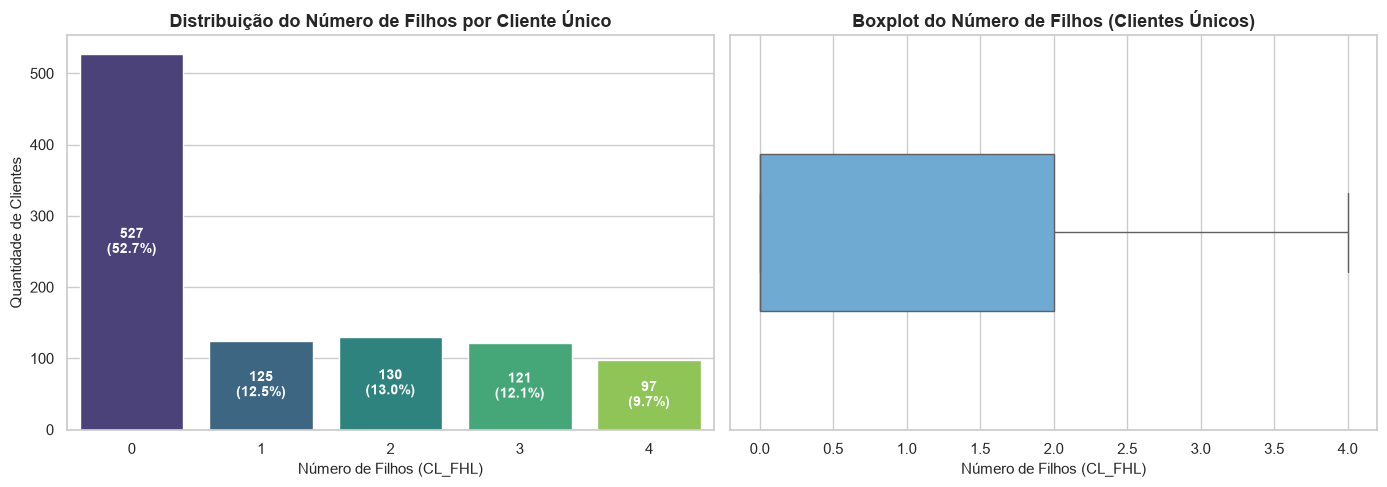

In [56]:
# Visualização da distribuição de filhos: Histograma e Boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de Barras com Frequência e Percentual
cores = sns.color_palette("viridis", len(fhl_clientes.value_counts()))
ax1 = sns.countplot(x=fhl_clientes, hue=fhl_clientes, palette=cores, legend=False, ax=axes[0])
axes[0].set_title("Distribuição do Número de Filhos por Cliente Único", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Número de Filhos (CL_FHL)", fontsize=11)
axes[0].set_ylabel("Quantidade de Clientes", fontsize=11)

# Rótulos nas barras
total_c = len(fhl_clientes)
for p in ax1.patches:
    altura = p.get_height()
    pct = (altura / total_c) * 100
    ax1.annotate(f"{int(altura)}\n({pct:.1f}%)",
                 (p.get_x() + p.get_width() / 2., altura / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=10)

# 2. Boxplot detalhado
sns.boxplot(x=fhl_clientes, color="#5dade2", ax=axes[1], width=0.4)
axes[1].set_title("Boxplot do Número de Filhos (Clientes Únicos)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Número de Filhos (CL_FHL)", fontsize=11)

plt.tight_layout()
plt.show()
